# FIFISH E-GO ROV Log Analysis

Analysis of the **ROV Log** files exported from the FIFISH app of a QYSEA FIFISH E-GO underwater drone.
Each log is a time series (about 2 samples per second) of **depth, water temperature and orientation** of the ROV.
This notebook turns one log into:

- a **dive profile** and a table of the individual dives,
- a **temperature profile** against depth,
- **attitude, heading and stability** plots (how steady was the ROV, and therefore the video?),
- a clean CSV and a JSON summary,
- an optional **comparison of all logs** in the data folder.

Author: Alina Bauer, Eawag SURF (Remote Sensing), 2026.

**How to use it:** put the log files into `data/raw/`, set `LOG_ID` in section 1.2, then choose *Run All*.
Results are written to `outputs/log_<ID>/`.

### Contents
1. [Setup](#1.-Setup)
2. [Load the log](#2.-Load-the-log)
3. [Quality control](#3.-Quality-control)
4. [Phases of the session and individual dives](#4.-Phases-of-the-session-and-individual-dives)
5. [Plots](#5.-Plots)
6. [Export](#6.-Export-clean-data-and-summary)
7. [Compare all logs](#7.-Compare-all-logs)
8. [Notes and limitations](#8.-Notes-and-limitations)

## 1. Setup

### 1.1 Imports

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

### 1.2 Settings

This is the only cell you normally need to edit. All paths are **relative to this notebook**
(it lives in `notebooks/`), so the project runs on any computer without changes.

In [2]:
# --- Where things are -------------------------------------------------------
DATA_DIR = Path("../data/raw")      # exported ROV log files (.json)
OUTPUT_ROOT = Path("../outputs")    # one sub-folder per log is created here

# --- Which log to analyse ---------------------------------------------------
# Any part of the file name that identifies ONE log. The number at the end of
# the name (time of export) is the easiest, e.g. "ROV-Log-...-1020111815.json".
LOG_ID = "1020111815"

# Overlay ALL logs found in DATA_DIR in section 7?
COMPARE_ALL = True

# --- Analysis parameters ----------------------------------------------------
TIMEZONE = "Europe/Zurich"      # log timestamps are UTC milliseconds
DIVE_DEPTH_THRESHOLD = 0.3      # m: deeper than this counts as "diving"
GAP_S = 2.0                     # s: a pause longer than this is a "gap" in the log
TEMP_DROP_C = 0.4               # degC: temperature drop used to detect water entry
MERGE_SURFACE_S = 20            # s: dips closer together than this form one dive
MIN_DIVE_M = 0.5                # m: ignore dips shallower than this
WATER_ENTRY_S = None            # set by hand (seconds since log start) if the automatic detection is wrong

### 1.3 Helper functions

- `load_log` reads a JSON log into a table (one row per sample) and a table of *events* (button presses such as "photo").
- `detect_water_entry` finds the moment the ROV went into the water. The log starts when the app connects, so the first minutes are often on shore. Depth reads 0 both in air and at the surface, so the **temperature drop** (warm ROV in air to cold lake water) or the **first dive deeper than the threshold** is used, whichever comes first.
- `break_gaps` inserts an empty row at every gap so plot lines are interrupted instead of drawing a false straight line across missing data.

In [3]:
SENSOR_TYPES = ["depth", "attitude", "water_sensor"]


def load_log(path, timezone=TIMEZONE):
    """Read one ROV log (JSON). Returns (samples table, events table)."""
    with open(path) as f:
        records = json.load(f)

    # One table per record type; they share the same timestamps, so they can be merged.
    tables = {}
    for record_type in {r["type"] for r in records}:
        rows = [{"ts": r["timestamp"], **r["payload"]} for r in records if r["type"] == record_type]
        tables[record_type] = pd.DataFrame(rows).drop_duplicates("ts")

    log = tables["depth"]                      # contains depth AND temperature
    for record_type in ("attitude", "water_sensor"):
        if record_type in tables:
            log = log.merge(tables[record_type], on="ts", how="left")
    for column in ["pitch", "roll", "yaw", "ph", "salt", "ntu", "doValue"]:
        if column not in log:
            log[column] = np.nan               # keep the same columns for every log
    log = log.sort_values("ts").reset_index(drop=True)
    log["datetime"] = pd.to_datetime(log["ts"], unit="ms", utc=True).dt.tz_convert(timezone)
    log["t"] = (log["ts"] - log["ts"].iloc[0]) / 1000.0     # seconds since log start

    # Everything that is not a regular sensor sample, e.g. "photo" button presses.
    event_rows = [{"ts": r["timestamp"], "type": r["type"], **r["payload"]}
                  for r in records if r["type"] not in SENSOR_TYPES]
    events = pd.DataFrame(event_rows, columns=["ts", "type"]) if not event_rows else pd.DataFrame(event_rows)
    if len(events):
        events["datetime"] = pd.to_datetime(events["ts"], unit="ms", utc=True).dt.tz_convert(timezone)
        events["t"] = (events["ts"] - log["ts"].iloc[0]) / 1000.0
    return log, events


def detect_water_entry(log, temp_drop=TEMP_DROP_C, depth_threshold=DIVE_DEPTH_THRESHOLD):
    """Seconds since log start at which the ROV entered the water."""
    candidates = []
    start_temp = log["temperature"].iloc[:20].median()
    smoothed = log["temperature"].rolling(9, center=True, min_periods=1).median()
    cooled = log[smoothed < start_temp - temp_drop]
    if len(cooled):
        candidates.append(cooled["t"].iloc[0])
    deep = log[log["depth"] > depth_threshold]
    if len(deep):
        candidates.append(deep["t"].iloc[0])
    return float(min(candidates)) if candidates else 0.0


def break_gaps(table, gap_s=GAP_S):
    """Insert an empty row at every gap so that lines are interrupted in plots."""
    after_gap = table["t"].diff() > gap_s
    idx = table.index[after_gap]
    if len(idx) == 0:
        return table
    blanks = pd.DataFrame({"t": table.loc[idx, "t"].values - 0.001}, index=idx - 0.5)
    return pd.concat([table, blanks]).sort_index()

## 2. Load the log

### 2.1 Choose the log file
The notebook lists all logs in `data/raw/` and selects the one matching `LOG_ID`.

In [4]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Folder '{DATA_DIR}' not found. This notebook is running in: {Path.cwd()}\n"
        "Open it from the 'notebooks' folder of the repository and put the ROV log "
        "files into 'data/raw' (see README).")

all_logs = sorted(p for p in DATA_DIR.glob("ROV-Log*") if p.is_file())
print(f"Logs found in {DATA_DIR}:")
for path in all_logs:
    print("  ", path.name)

matches = [p for p in all_logs if LOG_ID in p.name]
if len(matches) != 1:
    raise ValueError(f"LOG_ID = '{LOG_ID}' matches {len(matches)} files. "
                     "Use a more specific part of the file name (see the list above).")
LOG_FILE = matches[0]
OUT_DIR = OUTPUT_ROOT / f"log_{LOG_FILE.stem.split('-')[-1]}"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"\nAnalysing: {LOG_FILE.name}\nResults are saved to: {OUT_DIR}")

Logs found in ../data/raw:
   ROV-Log-2026-10-17-2026-10-20-1020111815.json
   ROV-Log-2026-10-17-2026-10-20-1020113121.json

Analysing: ROV-Log-2026-10-17-2026-10-20-1020111815.json
Results are saved to: ../outputs/log_1020111815


### 2.2 Read it into a table

A log file is a list of records `{"type", "timestamp", "payload"}`. There are three sensor record types
(`depth` with depth and temperature, `attitude` with yaw/pitch/roll, `water_sensor` with pH, salinity, turbidity and dissolved oxygen)
plus optional **events** such as a photo button press. One row of the table below is one sample.

In [5]:
log, events = load_log(LOG_FILE)
print(f"{len(log)} samples, columns: {list(log.columns)}")
log.head()

3119 samples, columns: ['ts', 'depth', 'temperature', 'yaw', 'roll', 'pitch', 'ph', 'salt', 'ntu', 'doValue', 'datetime', 't']


,ts,depth,temperature,yaw,roll,pitch,ph,salt,ntu,doValue,datetime,t
0,1792485616608,0.0,18.87,102.430850,-0.847626,2.825562,0,0,0,0,2026-10-20 10:40:16.608000+02:00,0.000
1,1792485617126,0.0,18.88,102.508120,-0.848175,2.825989,0,0,0,0,2026-10-20 10:40:17.126000+02:00,0.518
2,1792485617651,0.0,18.81,102.469025,-0.851105,2.821228,0,0,0,0,2026-10-20 10:40:17.651000+02:00,1.043
3,1792485618176,0.0,18.88,102.491030,-0.841156,2.848999,0,0,0,0,2026-10-20 10:40:18.176000+02:00,1.568
4,1792485618687,0.0,18.88,102.435300,-0.849121,2.825165,0,0,0,0,2026-10-20 10:40:18.687000+02:00,2.079


Button presses logged by the app (useful as synchronisation points with the video):

In [6]:
events.drop(columns=["ts"]) if len(events) else print("No events in this log.")

,type,photo_type,datetime,t
0,photo,Video and Photo,2026-10-20 10:41:26.551000+02:00,69.943


## 3. Quality control

Before interpreting anything: how long is the log, how regular is the sampling, are there gaps, and was a water-quality sensor attached?
Gaps appear when the app lost the connection or logging was paused; in the plots they are shown as hatched grey areas.
The water-sensor channels stay at 0 when no sensor accessory is connected.

In [7]:
sample_dt = log["t"].diff()
print(f"Start:    {log.datetime.iloc[0]}")
print(f"End:      {log.datetime.iloc[-1]}")
print(f"Duration: {log.t.iloc[-1] / 60:.1f} min")
print(f"Median sampling interval: {sample_dt.median():.3f} s (about {1 / sample_dt.median():.1f} Hz)")

gaps = log.loc[sample_dt > GAP_S, ["datetime", "t"]].assign(gap_s=sample_dt[sample_dt > GAP_S])
print(f"\nGaps longer than {GAP_S:.0f} s: {len(gaps)}")
if len(gaps):
    print(gaps.to_string())
gap_spans = [(log.t.iloc[i - 1], log.t.iloc[i]) for i in np.where(sample_dt > GAP_S)[0]]

water_sensor_attached = bool(log[["ph", "salt", "ntu", "doValue"]].abs().sum().sum() > 0)
print(f"\nWater-quality sensor attached (any non-zero pH/salinity/NTU/DO)? {water_sensor_attached}")

log[["depth", "temperature", "yaw", "pitch", "roll"]].describe().round(2)

Start:    2026-10-20 10:40:16.608000+02:00
End:      2026-10-20 11:18:09.393000+02:00
Duration: 37.9 min
Median sampling interval: 0.524 s (about 1.9 Hz)

Gaps longer than 2 s: 3
                            datetime         t    gap_s
105 2026-10-20 10:41:14.741000+02:00    58.133    3.634
149 2026-10-20 10:42:04.159000+02:00   107.551   26.881
984 2026-10-20 10:59:31.267000+02:00  1154.659  611.008

Water-quality sensor attached (any non-zero pH/salinity/NTU/DO)? False


,depth,temperature,yaw,pitch,roll
count,3119.00,3119.00,3119.00,3119.00,3119.00
mean,2.35,18.34,145.98,-16.31,-1.06
std,3.51,0.41,90.00,29.37,8.42
min,0.00,16.53,0.18,-176.91,-87.03
25%,0.00,18.29,78.30,-17.49,-0.63
50%,0.38,18.37,121.33,-16.39,-0.03
75%,2.84,18.39,222.62,-1.13,0.35
max,11.76,19.07,359.96,175.77,21.58


## 4. Phases of the session and individual dives

### 4.1 Phases
Each sample is labelled as
- **on shore**: before water entry,
- **surface**: in the water, shallower than `DIVE_DEPTH_THRESHOLD`,
- **diving**: deeper than `DIVE_DEPTH_THRESHOLD`.

`in_water` contains only the samples after water entry and is used for all temperature statistics.

In [8]:
water_entry_s = detect_water_entry(log) if WATER_ENTRY_S is None else WATER_ENTRY_S
entry_clock = log.loc[log.t >= water_entry_s, "datetime"].iloc[0]
print(f"Water entry: t = {water_entry_s:.0f} s ({entry_clock:%H:%M:%S})")

log["phase"] = "on shore"
log.loc[log.t >= water_entry_s, "phase"] = "surface"
log.loc[(log.t >= water_entry_s) & (log.depth > DIVE_DEPTH_THRESHOLD), "phase"] = "diving"
in_water = log[log.t >= water_entry_s].copy()

seconds_per_phase = log.groupby("phase")["t"].agg(lambda s: len(s) * sample_dt.median()).round(0)
print("\nTime spent per phase (s):")
print(seconds_per_phase.to_string())

Water entry: t = 214 s (10:43:51)



Time spent per phase (s):
phase
diving      853.0
on shore    185.0
surface     597.0


### 4.2 Plot helper functions
Small functions shared by all plots below (background colouring by phase, markers for events, legend, saving).

In [9]:
PHASE_COLORS = {"on shore": "#d9d3c2", "surface": "#a8d5e2", "diving": "#1e7a85"}
EVENT_COLOR = "#c0392b"


def shade_phases(ax, log, gap_spans):
    """Colour the background by phase; hatched grey marks gaps without data."""
    start = 0
    for i in range(1, len(log) + 1):
        if i == len(log) or log.phase.iloc[i] != log.phase.iloc[start]:
            ax.axvspan(log.t.iloc[start] / 60, log.t.iloc[i - 1] / 60,
                       color=PHASE_COLORS[log.phase.iloc[start]], alpha=0.25, lw=0)
            start = i
    for gap_start, gap_end in gap_spans:
        ax.axvspan(gap_start / 60, gap_end / 60, facecolor="white", edgecolor="grey",
                   hatch="///", alpha=0.9, lw=0, zorder=3)


def mark_events(ax, events):
    """Dotted vertical line at each logged button press (photo/record)."""
    for _, event in events.iterrows():
        ax.axvline(event["t"] / 60, color=EVENT_COLOR, ls=":", lw=1.2, zorder=4)


def add_legend(ax, gap_spans, events):
    """Legend entries for the phase colours, gaps and events."""
    for name, color in PHASE_COLORS.items():
        ax.plot([], [], color=color, lw=8, alpha=0.5, label=name)
    if gap_spans:
        ax.fill_between([], [], [], facecolor="white", edgecolor="grey", hatch="///", label="log gap")
    if len(events):
        ax.plot([], [], color=EVENT_COLOR, ls=":", label="photo/record event")
    ax.legend(loc="lower right", fontsize=8)


def save_and_show(fig, filename, out_dir=OUT_DIR):
    """Save a figure to the output folder and display it in the notebook."""
    fig.savefig(out_dir / filename)
    plt.show()
    plt.close(fig)

### 4.3 Individual dives

A single log usually contains several dives. Dips that are closer together than `MERGE_SURFACE_S` are counted as one dive;
dips shallower than `MIN_DIVE_M` are ignored. The temperature columns describe what the ROV sensor reported during each dive.

In [10]:
is_diving = (log.t >= water_entry_s) & (log.depth > DIVE_DEPTH_THRESHOLD)
run_id = (is_diving != is_diving.shift()).cumsum()
runs_below_threshold = [(g.t.iloc[0], g.t.iloc[-1]) for _, g in log[is_diving].groupby(run_id[is_diving])]

# merge dives separated by only a short surface interval
merged_dives = []
for start, end in runs_below_threshold:
    if merged_dives and start - merged_dives[-1][1] < MERGE_SURFACE_S:
        merged_dives[-1] = (merged_dives[-1][0], end)
    else:
        merged_dives.append((start, end))

dive_rows = []
for start, end in merged_dives:
    dive = log[(log.t >= start) & (log.t <= end)]
    if dive.depth.max() < MIN_DIVE_M:
        continue
    deepest = dive.loc[dive.depth.idxmax()]
    dive_rows.append({
        "dive": len(dive_rows) + 1,
        "start": f"{dive.datetime.iloc[0]:%H:%M:%S}",
        "duration_min": round((end - start) / 60, 1),
        "max_depth_m": round(dive.depth.max(), 2),
        "mean_depth_m": round(dive.depth.mean(), 2),
        "temp_at_max_depth_C": round(deepest.temperature, 2),
        "temp_min_C": round(dive.temperature.min(), 2),
        "temp_max_C": round(dive.temperature.max(), 2),
    })
dive_table = pd.DataFrame(dive_rows)
dive_table.to_csv(OUT_DIR / "dive_table.csv", index=False)
dive_table

,dive,start,duration_min,max_depth_m,mean_depth_m,temp_at_max_depth_C,temp_min_C,temp_max_C
0,1,10:44:34,1.8,9.40,7.14,18.39,18.30,18.39
1,2,10:47:19,0.2,0.83,0.63,18.39,18.39,18.39
2,3,11:00:33,3.9,3.87,1.58,18.29,18.29,18.67
3,4,11:05:23,10.6,11.76,4.18,18.00,16.53,18.39
4,5,11:16:29,0.3,0.72,0.21,18.39,18.39,18.39


## 5. Plots

All figures are saved as PNG files in the output folder of this log.

### 5.1 Dive profile
Depth over time. Each dip below the surface is a dive; flat steps show where depth hold was used.
Dotted red lines mark photo/record events, hatched areas are gaps in the log.

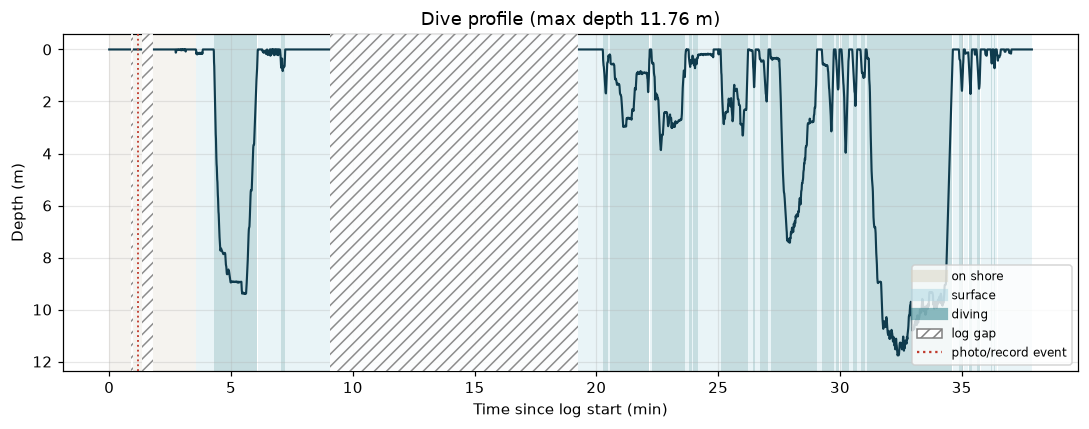

In [11]:
plot_df = break_gaps(log)

fig, ax = plt.subplots(figsize=(10, 4))
shade_phases(ax, log, gap_spans)
mark_events(ax, events)
ax.plot(plot_df.t / 60, plot_df.depth, color="#0f3b4d", lw=1.4)
ax.invert_yaxis()
ax.set_xlabel("Time since log start (min)")
ax.set_ylabel("Depth (m)")
ax.set_title(f"Dive profile (max depth {log.depth.max():.2f} m)")
add_legend(ax, gap_spans, events)
fig.tight_layout()
save_and_show(fig, "1_dive_profile.png")

### 5.2 Temperature over time
The temperature sensor sits **inside the ROV**, so it responds slowly: right after water entry the curve is the sensor
cooling down (it can take several minutes), not the lake. Only read the plateau after it has stabilised.

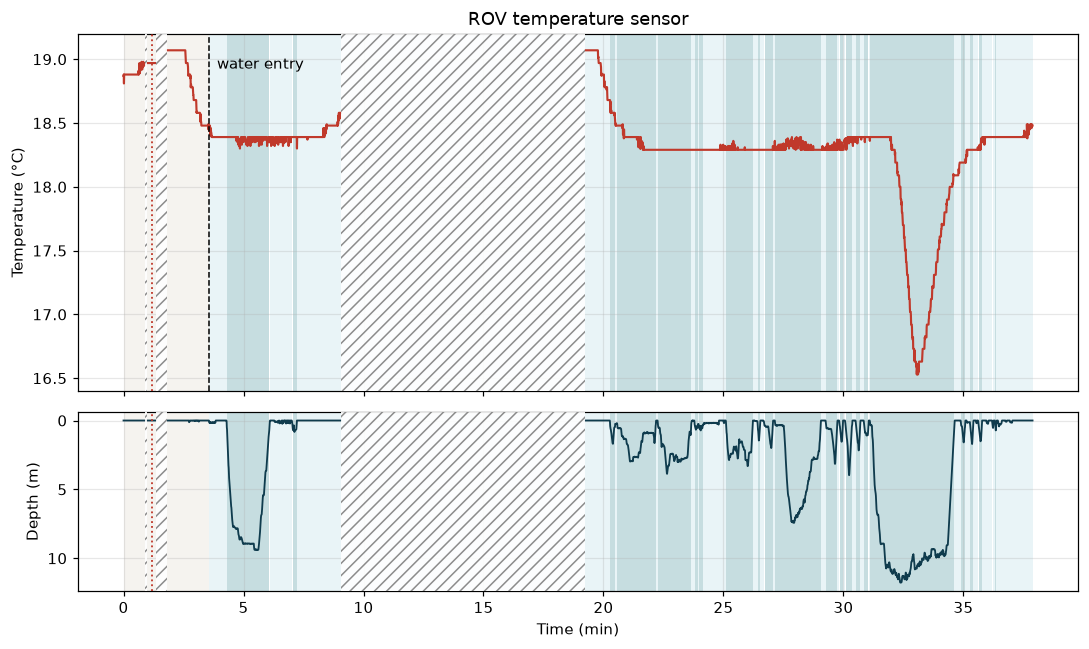

In [12]:
fig, (ax_temp, ax_depth) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                                        gridspec_kw={"height_ratios": [2, 1]})
for ax in (ax_temp, ax_depth):
    shade_phases(ax, log, gap_spans)
    mark_events(ax, events)
ax_temp.plot(plot_df.t / 60, plot_df.temperature, color="#c0392b", lw=1.4)
ax_temp.set_ylabel("Temperature (°C)")
ax_temp.set_title("ROV temperature sensor")
ax_temp.axvline(water_entry_s / 60, color="k", ls="--", lw=1)
ax_temp.annotate("water entry", (water_entry_s / 60, log.temperature.max()),
                 xytext=(5, -12), textcoords="offset points")
ax_depth.plot(plot_df.t / 60, plot_df.depth, color="#0f3b4d", lw=1.2)
ax_depth.invert_yaxis()
ax_depth.set_ylabel("Depth (m)")
ax_depth.set_xlabel("Time (min)")
fig.tight_layout()
save_and_show(fig, "2_temperature_time.png")

### 5.3 Temperature against depth
Samples in the water, coloured by time. If the descent and ascent traces differ at the same depth, that is the sensor lag.
A clear temperature decrease with depth may indicate a thermocline, but this should be **verified with an independent
measurement** (CTD, model or satellite product) because of the lag and the uncalibrated sensor.
The table gives the temperature statistics per 1 m depth bin.

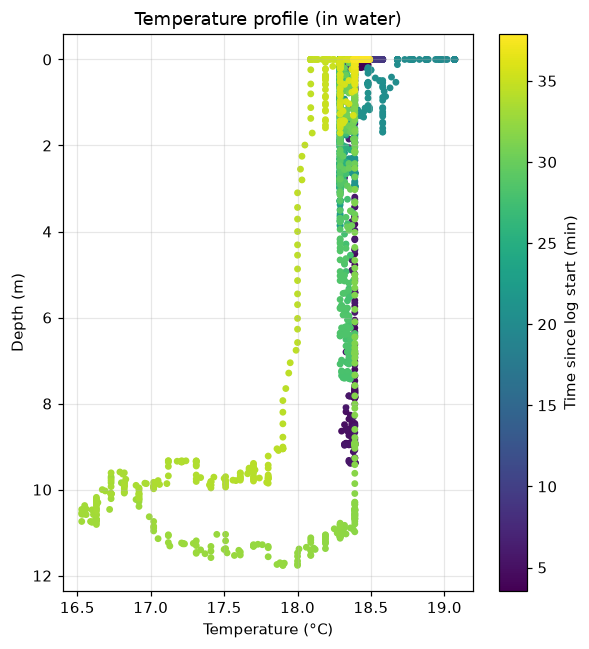

,count,mean,min,max
depth_bin_m (from),,,,
0,364,18.33,18.09,18.67
1,243,18.33,18.05,18.58
2,300,18.31,18.02,18.39
3,68,18.31,18.00,18.39
4,33,18.30,18.00,18.39
5,48,18.33,18.00,18.39
6,69,18.34,17.99,18.39
7,66,18.34,17.90,18.39
8,107,18.36,17.90,18.39


In [13]:
fig, ax = plt.subplots(figsize=(5.5, 6))
points = ax.scatter(in_water.temperature, in_water.depth, c=in_water.t / 60, cmap="viridis", s=12)
ax.invert_yaxis()
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Depth (m)")
ax.set_title("Temperature profile (in water)")
fig.colorbar(points, label="Time since log start (min)")
fig.tight_layout()
save_and_show(fig, "3_temperature_profile.png")

diving_samples = in_water[in_water.depth > DIVE_DEPTH_THRESHOLD]
temp_per_depth_bin = pd.DataFrame()
if len(diving_samples):
    temp_per_depth_bin = (diving_samples.groupby(np.floor(diving_samples.depth).astype(int))["temperature"]
                          .agg(["count", "mean", "min", "max"]).round(2))
    temp_per_depth_bin.index.name = "depth_bin_m (from)"
    temp_per_depth_bin.to_csv(OUT_DIR / "temperature_per_depth_bin.csv")
temp_per_depth_bin

### 5.4 Attitude: pitch, roll and heading
Large pitch spikes appear when the ROV is carried or lifted by hand (on shore, at the end of the session).
Heading (`yaw`) is 0° towards north and comes from the ROV compass, which needs a regular sensor calibration (see the FIFISH manual).

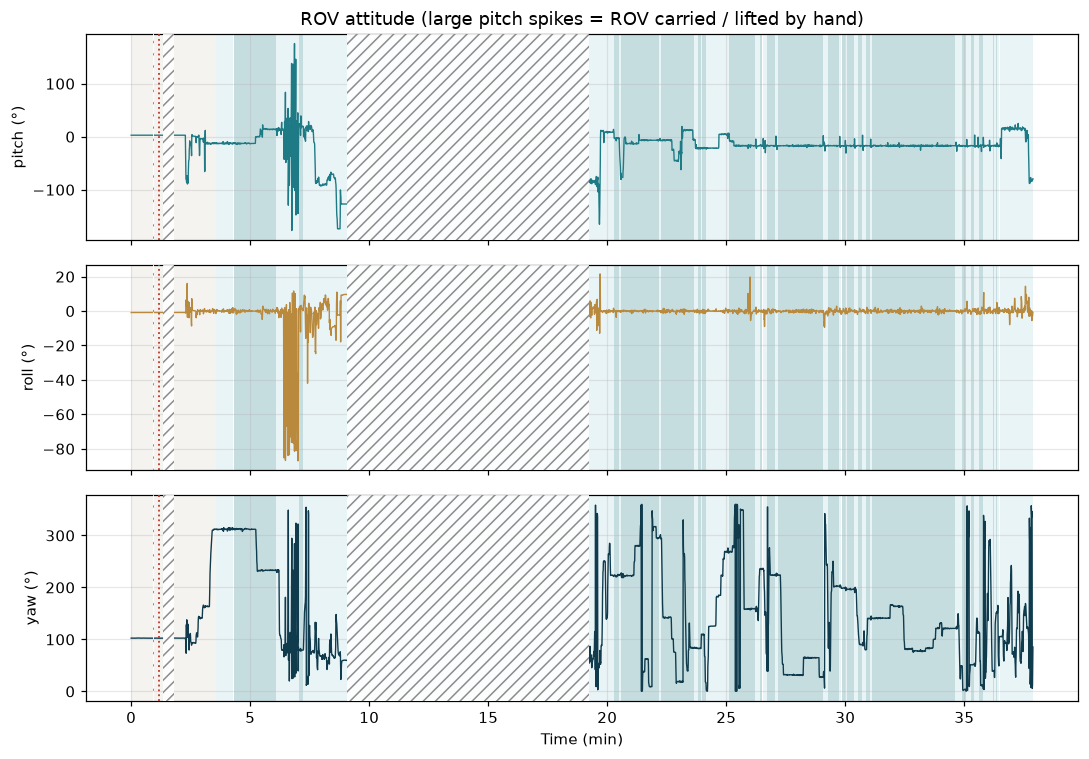

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, column, color in zip(axes, ["pitch", "roll", "yaw"], ["#1e7a85", "#b98a3e", "#0f3b4d"]):
    shade_phases(ax, log, gap_spans)
    mark_events(ax, events)
    ax.plot(plot_df.t / 60, plot_df[column], color=color, lw=0.9)
    ax.set_ylabel(f"{column} (°)")
axes[0].set_title("ROV attitude (large pitch spikes = ROV carried / lifted by hand)")
axes[-1].set_xlabel("Time (min)")
fig.tight_layout()
save_and_show(fig, "4_attitude.png")

### 5.5 Heading distribution
In which compass directions was the camera pointing while the ROV was in the water?

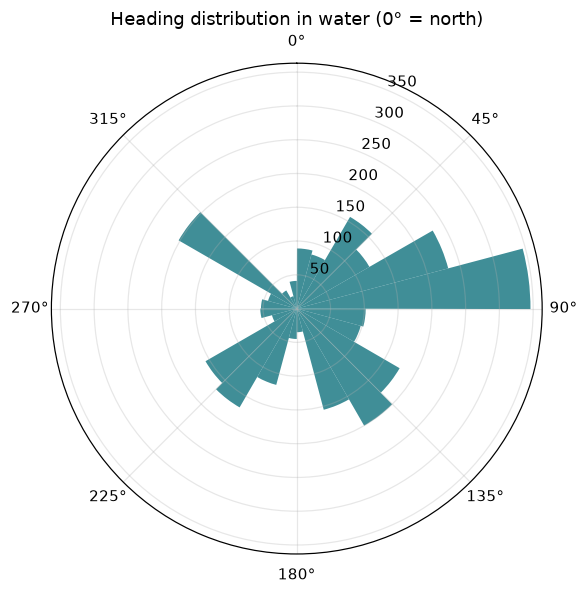

In [15]:
heading_rad = np.deg2rad(in_water.yaw.dropna().values)
fig = plt.figure(figsize=(5.5, 5.5))
ax = fig.add_subplot(111, projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.hist(heading_rad, bins=24, color="#1e7a85", alpha=0.85)
ax.set_title("Heading distribution in water (0° = north)")
fig.tight_layout()
save_and_show(fig, "5_heading_rose.png")

### 5.6 Vertical speed and stability
- **Vertical speed**: change of depth per second (positive = descending), smoothed with a rolling median.
- **Stability**: rolling standard deviation of pitch and roll. Low values mean a steady ROV and therefore steadier video;
  this helps to choose the best segments for video analysis (and to compare piloting modes).

Both are computed separately inside each continuous part of the log, so gaps do not create artefacts.

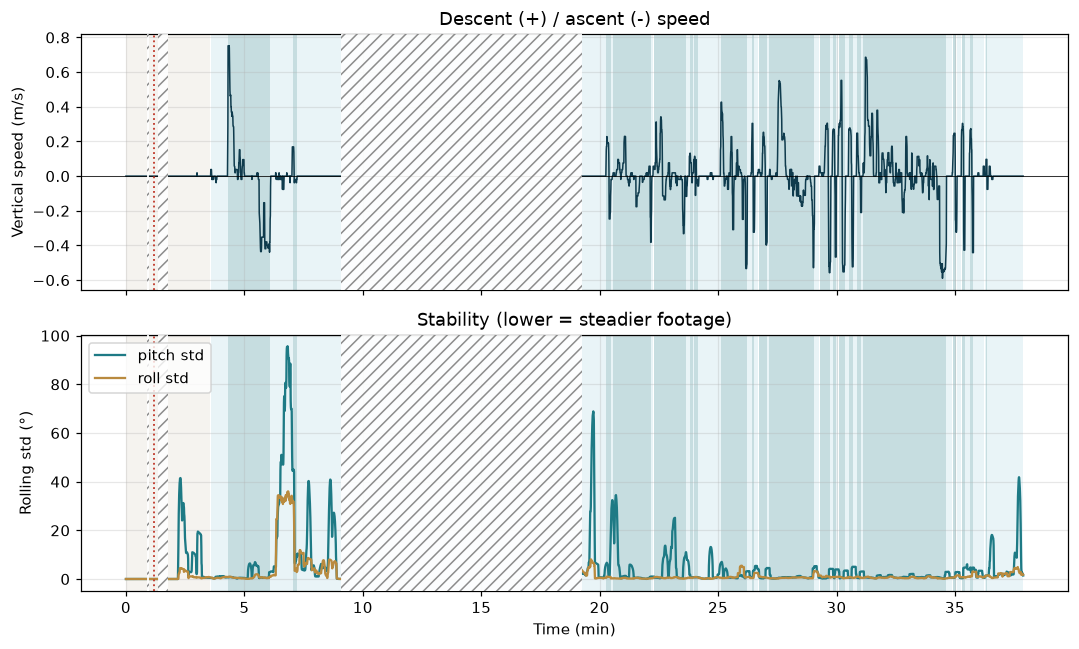

In [16]:
segment_id = (sample_dt > GAP_S).cumsum()
log["vz"] = log["depth"].diff() / log["t"].diff()
log.loc[sample_dt > GAP_S, "vz"] = np.nan
log["vz_smooth"] = log.groupby(segment_id)["vz"].transform(
    lambda s: s.rolling(9, center=True, min_periods=3).median())
log["stability_pitch"] = log.groupby(segment_id)["pitch"].transform(
    lambda s: s.rolling(20, center=True, min_periods=5).std())
log["stability_roll"] = log.groupby(segment_id)["roll"].transform(
    lambda s: s.rolling(20, center=True, min_periods=5).std())
plot_df = break_gaps(log)

fig, (ax_speed, ax_stab) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax in (ax_speed, ax_stab):
    shade_phases(ax, log, gap_spans)
    mark_events(ax, events)
ax_speed.plot(plot_df.t / 60, plot_df.vz_smooth, color="#0f3b4d", lw=1)
ax_speed.axhline(0, color="k", lw=0.5)
ax_speed.set_ylabel("Vertical speed (m/s)")
ax_speed.set_title("Descent (+) / ascent (-) speed")
ax_stab.plot(plot_df.t / 60, plot_df.stability_pitch, label="pitch std", color="#1e7a85")
ax_stab.plot(plot_df.t / 60, plot_df.stability_roll, label="roll std", color="#b98a3e")
ax_stab.set_ylabel("Rolling std (°)")
ax_stab.set_xlabel("Time (min)")
ax_stab.set_title("Stability (lower = steadier footage)")
ax_stab.legend()
fig.tight_layout()
save_and_show(fig, "6_speed_stability.png")

### 5.7 Time spent at each depth
How much footage can be expected from each depth layer?

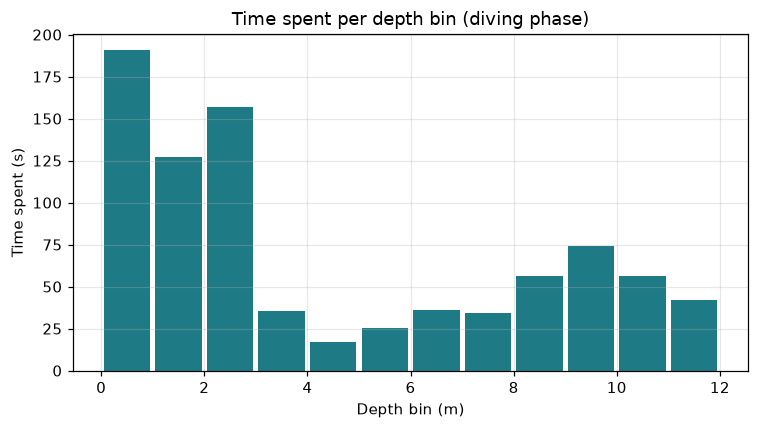

In [17]:
depth_bins = np.arange(0, np.ceil(log.depth.max()) + 1, 1)
seconds_per_bin = np.histogram(diving_samples.depth, bins=depth_bins)[0] * sample_dt.median()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(depth_bins[:-1] + 0.5, seconds_per_bin, width=0.9, color="#1e7a85")
ax.set_xlabel("Depth bin (m)")
ax.set_ylabel("Time spent (s)")
ax.set_title("Time spent per depth bin (diving phase)")
fig.tight_layout()
save_and_show(fig, "7_time_per_depth.png")

## 6. Export clean data and summary

- `rov_log_clean.csv`: the full table with all derived columns (phase, vertical speed, stability),
- `dive_summary.json`: the key numbers of this log in one file.

In [18]:
log.to_csv(OUT_DIR / "rov_log_clean.csv", index=False)

deepest_sample = log.loc[log.depth.idxmax()]
summary = {
    "log_file": LOG_FILE.name,
    "start": str(log.datetime.iloc[0]),
    "end": str(log.datetime.iloc[-1]),
    "duration_min": round(log.t.iloc[-1] / 60, 1),
    "n_gaps": int(len(gaps)),
    "gap_total_min": round(float(gaps.gap_s.sum()) / 60, 1) if len(gaps) else 0.0,
    "water_entry_s": round(water_entry_s),
    "n_dives": int(len(dive_table)),
    "max_depth_m": float(log.depth.max()),
    "time_max_depth": str(deepest_sample.datetime),
    "temp_at_max_depth_C": float(deepest_sample.temperature),
    "water_temp_median_C": round(float(in_water.temperature.median()), 2),
    "water_temp_range_C": [float(in_water.temperature.min()), float(in_water.temperature.max())],
    "seconds_below_threshold": round(len(diving_samples) * sample_dt.median()),
    "water_sensor_attached": water_sensor_attached,
    "events": [{"time": f"{e.datetime:%H:%M:%S}", "type": e["type"]} for _, e in events.iterrows()],
}
(OUT_DIR / "dive_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "log_file": "ROV-Log-2026-10-17-2026-10-20-1020111815.json",
  "start": "2026-10-20 10:40:16.608000+02:00",
  "end": "2026-10-20 11:18:09.393000+02:00",
  "duration_min": 37.9,
  "n_gaps": 3,
  "gap_total_min": 10.7,
  "water_entry_s": 214,
  "n_dives": 5,
  "max_depth_m": 11.76,
  "time_max_depth": "2026-10-20 11:12:38.528000+02:00",
  "temp_at_max_depth_C": 18.0,
  "water_temp_median_C": 18.34,
  "water_temp_range_C": [
    16.53,
    19.07
  ],
  "seconds_below_threshold": 853,
  "water_sensor_attached": false,
  "events": [
    {
      "time": "10:41:26",
      "type": "photo"
    }
  ]
}


## 7. Compare all logs

Overlays every log found in `data/raw/` (set `COMPARE_ALL = False` to skip). This is the start of a simple time series
across dives: duration, maximum depth, time spent diving, and the temperature profile of each log on the same axes.
Results go to `outputs/compare/`.

,log,duration_min,max_depth_m,time_diving_min,temp_median_C,temp_min_C,temp_max_C
0,20.10.2026 10:40,37.9,11.76,14.2,18.34,16.53,19.07
1,20.10.2026 11:19,11.4,6.72,5.3,18.39,18.35,18.49


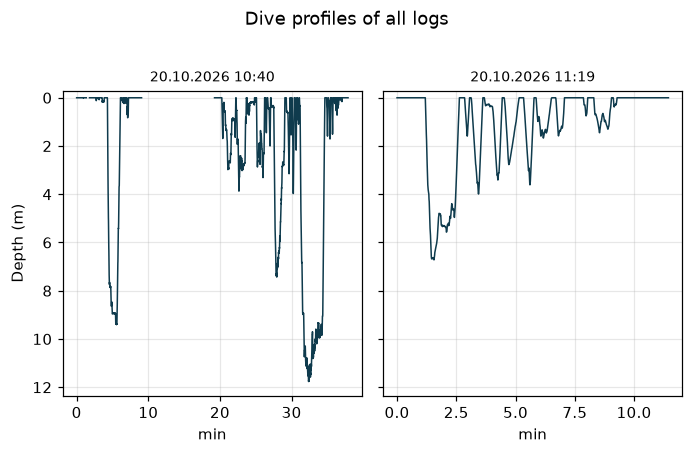

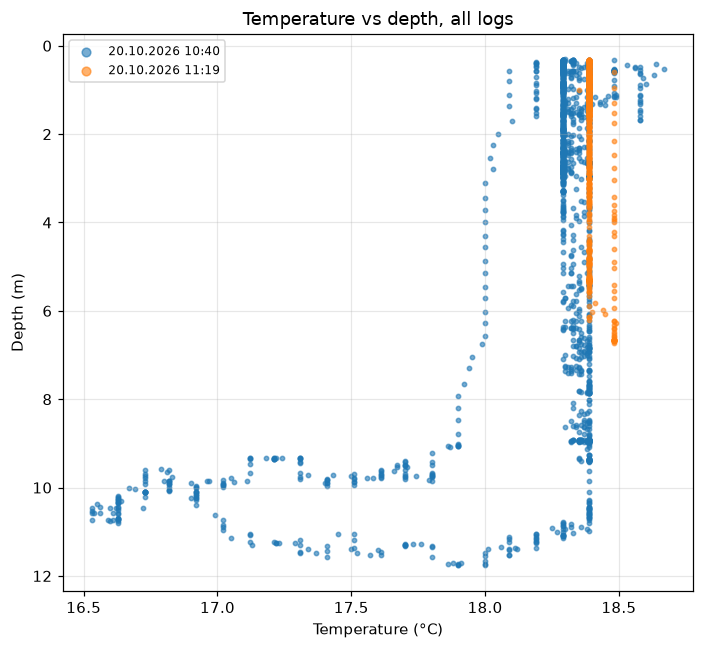

In [19]:
if COMPARE_ALL:
    COMPARE_DIR = OUTPUT_ROOT / "compare"
    COMPARE_DIR.mkdir(parents=True, exist_ok=True)

    # --- load every log and summarise it
    runs = []
    for path in all_logs:
        try:
            run_log, _ = load_log(path)
        except Exception as error:
            print(f"Skipping {path.name}: {error}")
            continue
        entry_s = detect_water_entry(run_log)
        run_in_water = run_log[run_log.t >= entry_s]
        runs.append({
            "name": path.name,
            "label": f"{run_log.datetime.iloc[0]:%d.%m.%Y %H:%M}",
            "log": run_log,
            "in_water": run_in_water,
            "diving": run_in_water[run_in_water.depth > DIVE_DEPTH_THRESHOLD],
        })
    runs.sort(key=lambda run: run["log"].ts.iloc[0])

    # --- (a) overview table
    comparison = pd.DataFrame([{
        "log": run["label"],
        "file": run["name"],
        "duration_min": round(run["log"].t.iloc[-1] / 60, 1),
        "max_depth_m": run["log"].depth.max(),
        "time_diving_min": round(len(run["diving"]) * run["log"].t.diff().median() / 60, 1),
        "temp_median_C": round(run["in_water"].temperature.median(), 2),
        "temp_min_C": run["in_water"].temperature.min(),
        "temp_max_C": run["in_water"].temperature.max(),
    } for run in runs])
    comparison.to_csv(COMPARE_DIR / "comparison_summary.csv", index=False)
    display(comparison.drop(columns="file"))

    # --- (b) dive profiles side by side on the same depth axis
    fig, axes = plt.subplots(1, len(runs), figsize=(3.2 * len(runs), 4), sharey=True, squeeze=False)
    max_depth_all = max(run["log"].depth.max() for run in runs)
    for ax, run in zip(axes[0], runs):
        run_plot = break_gaps(run["log"])
        ax.plot(run_plot.t / 60, run_plot.depth, color="#0f3b4d", lw=1)
        ax.set_title(run["label"], fontsize=9)
        ax.set_xlabel("min")
        ax.set_ylim(max_depth_all * 1.05, -0.3)
    axes[0][0].set_ylabel("Depth (m)")
    fig.suptitle("Dive profiles of all logs", y=1.02)
    fig.tight_layout()
    fig.savefig(COMPARE_DIR / "compare_dive_profiles.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # --- (c) temperature against depth, all logs in one plot (diving samples only)
    fig, ax = plt.subplots(figsize=(6.5, 6))
    colors = plt.get_cmap("tab10")
    for i, run in enumerate(runs):
        if len(run["diving"]):
            ax.scatter(run["diving"].temperature, run["diving"].depth, s=8, alpha=0.6,
                       color=colors(i % 10), label=run["label"])
    ax.invert_yaxis()
    ax.set_xlabel("Temperature (°C)")
    ax.set_ylabel("Depth (m)")
    ax.set_title("Temperature vs depth, all logs")
    ax.legend(fontsize=8, markerscale=2)
    fig.tight_layout()
    fig.savefig(COMPARE_DIR / "compare_temperature_profiles.png")
    plt.show()
    plt.close(fig)

## 8. Notes and limitations

- **Temperature sensor:** it is inside the ROV, uncalibrated and slow to respond (minutes). Use it for relative patterns
  and compare against an independent reference (CTD, model, satellite surface temperature) before drawing conclusions.
- **Depth:** from a pressure sensor with 0.01 m resolution; it reads 0 both in air and at the surface.
- **No positions:** without the optional U-QPS GPS module the log contains no coordinates, so dives cannot be mapped from the log alone.
- **Water-quality channels** (pH, salinity, turbidity, dissolved oxygen) are only filled if the corresponding sensor accessory is attached.
- **Water-entry detection** is heuristic (temperature drop or first dive); override it with `WATER_ENTRY_S` if it looks wrong in the plots.
- **Logs and video are separate files.** Use the logged photo/record events or the clock time to synchronise them.

*Source of the log format: FIFISH E-GO user manual V1.6 (ROV Log: Toolbox, then Help, then ROV Log, export as JSON or GPX).*